# Is a still mite's score the end of a random walk?

`report/fourier_and_brownian_motion.md` argues that a still mite's score behaves like Brownian motion: the score is the length of a sum of 128 little arrows, one per direction round the mite, and for a still mite those arrows are noise, so their sum is the end point of a **random walk**. If that is right, the score of a still recording is **Rayleigh-distributed**, and its size is set by the noise alone.

This notebook checks the argument one step at a time, each with its own figures:

| Step | Question |
|---|---|
| 1 | What exactly is the score? (the profile round the mite, its arrows, the walk they make) |
| 2 | What does the theory predict? (a simulated random walk) |
| 3 | Does the real walk spread like a random walk? |
| 4 | Are its steps independent? |
| 5 | Is the noise white over the frames? |
| 6 | A scale σ from the noise alone, which a moving leg hardly touches |
| 7 | Is the end point a round 2-D Gaussian? |
| 8 | Is score / σ Rayleigh-distributed? |
| 9 | Where the high still scores come from: slow change |
| 10 | Does the order of the rays matter? |
| 11 | Is the direction new in every recording? |
| 12 | How the scale depends on the number of frames |
| 13 | What this means for moving against still, and for the threshold |
| 14 | The argument, step by step |

**Data.** The recordings of `notebooks/outline_fourier.ipynb`: every labelled moving or still recording of six datasets, `Ground_truth_oct_26_final` only before its first poke (its plates shake after). The long run is left out because its labels are the score's own calls, which cuts its still recordings off at the threshold. `scripts/outline_fourier.py` saved each recording's outline taken apart in two directions at once, $C[f, h]$: $f$ the frequency over the frames, $h$ the harmonic round the mite. Nothing here scores frames again.

## Findings

**Yes, for the noise. A still recording's score is the end point of a random walk round the mite, and divided by a scale measured from the outline's own noise it follows the Rayleigh distribution, with nothing fitted. On top of the noise, part of the still recordings carry a small, slow, real change that the theory doesn't describe, and that makes the high still scores.**

- **The steps of the walk are correlated over a few rays** (neighbouring rays read overlapping pixels). That keeps the random walk and its Gaussian end point, but the report's scale $\tau/\sqrt{2K}$ is 1.8 times too small: σ has to be measured.
- **All round the mite the outline's noise is white over the frames**, never $1/f^2$. "Brownian" holds for the walk round the mite, not over the frames.
- **σ measured at the high frame frequencies** (the noise's level where slow changes don't reach) **predicts the still scores without anything fitted.** Still recordings carrying only noise are on the theory up to the 90th percentile in all six datasets (medians 1.20 to 1.39 against 1.18 to 1.20). In the 10-frame datasets, all still recordings together are close too.
- **The high still scores are slow changes, not noise.** They carry their power at the lowest frame frequencies, like a moving mite but much smaller: 15 to 36 % of still recordings, and 67 to 100 % of those above the theory's 99th percentile. Longer recordings catch more of them.
- **Part of that slow change is shared by the plate**: still arrows of all mites prefer one direction in the image (2 to 4 times the noise level in the 30- and 90-frame datasets), and consecutive still recordings of a mite keep their direction. Possibly a light gradient that changes during the recording, or a slow drift of the image: this notebook can't tell which.
- **The threshold is far beyond the noise.** On `poke_test_oct`, noise alone would put about 10⁻⁴⁵ of still recordings above 0.074. What brings still scores near the threshold is slow change.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "scripts")]

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats
from sklearn.metrics import roc_auc_score

%matplotlib inline

BLUE, ORANGE, AQUA, GREY, PURPLE = "#2a78d6", "#eb6834", "#1baf7a", "#8d8c85", "#8a5cd6"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3dc"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "legend.frameon": False, "legend.fontsize": 8.5, "lines.linewidth": 2,
})
np.seterr(divide="ignore", invalid="ignore")
rng = np.random.default_rng(0)

DATASETS = ["poke_test_oct", "GT_oct_2", "ground_truth_60min", "ground_truth_90min", "sample_data", "Ground_truth_oct_26_final"]
SHAKY_FROM = {"Ground_truth_oct_26_final": 30}   # its first poke: the plates shake from there on
K = 128                                          # rays round the mite
THETA = 2 * np.pi * np.arange(K) / K
STEP = np.exp(1j * THETA)                        # each ray's direction as a unit vector
THRESHOLD = 0.074                                # config.default.yaml: the poke run's F0.5 threshold (90 frames)
NOISE_H = slice(1, 6)                            # harmonics round the mite that measure the noise near h = 1 (step 6)
NEAR_H = slice(3, 11)                            # the harmonics next to h = 1 (step 6, for comparison)
SLOW = 2                                         # "slow change": twice the share of h = 1 power at low frequencies that noise gives (step 9)
LN2 = np.log(2)                                  # median / mean of the noise's power at one frequency (exponentially distributed)


def null_z(m, size):
    # score / sigma under the theory (step 6): a Rayleigh(1) end point divided by
    # sigma estimated from m noise values, sqrt(chi2(2m) / 2m)
    return stats.rayleigh.rvs(size=size, random_state=rng) / np.sqrt(rng.chisquare(2 * m, size) / (2 * m))


rows, spectra = [], {}
for name in DATASETS:
    kept = np.load(ROOT / "results" / "scripts" / f"outline_fourier_{name}.npz")
    S = kept["series"]                                   # (mites, recordings, f, h): the outline by frame frequency and harmonic
    C = S.sum(axis=2)                                    # summed over the frames' frequencies: the DFT of the app's profile, C_0 .. C_64
    chosen = kept["labelled"] & (np.abs(C[..., 0]) > 0)
    chosen[:, SHAKY_FROM.get(name, chosen.shape[1]):] = False
    N, F = int(kept["frames"]), S.shape[2]
    S, C, moving_here = S[chosen], C[chosen], kept["moving"][chosen]
    profile = np.fft.irfft(C * K, n=K, axis=-1)          # a_k: the app's profile, in noise floors

    # the variance of |C[f, h]|^2 over the frames: every f alike for white noise, half for the Nyquist term (N even)
    weight = np.ones(F)
    if N % 2 == 0:
        weight[-1] = 0.5
    high = np.arange(F // 2, F - (N % 2 == 0))           # the upper half of the frequencies, Nyquist left out
    per_f = (np.abs(S[:, high, NOISE_H]) ** 2).mean(axis=(1, 2))
    sigma_noise = np.sqrt(per_f * weight.sum() / 2)
    low = max(1, F // 5)                                 # the lowest fifth of the frequencies
    h1_power = np.abs(S[:, :, 1]) ** 2 / weight
    slow_share = (h1_power[:, :low] * weight[:low]).sum(axis=1) / (h1_power * weight).sum(axis=1)

    eps = profile - profile.mean(axis=1, keepdims=True)
    tau = eps.std(axis=1)
    mites, recordings = np.nonzero(chosen)
    for i in range(len(C)):
        rows.append({
            "dataset": name, "frames": N, "mite": f"{name}/{kept['mites'][mites[i]]}", "recording": recordings[i],
            "moving": bool(moving_here[i]), "app": float(kept["app"][chosen][i]), "score": float(abs(C[i, 1])),
            "abar": float(profile[i].mean()), "tau": float(tau[i]),
            "sigma_white": float(tau[i] / np.sqrt(2 * K)),
            "sigma_near": float(np.sqrt((np.abs(C[i, NEAR_H]) ** 2).mean() / 2)),
            "sigma_noise": float(sigma_noise[i]), "noise_values": high.size * (NOISE_H.stop - NOISE_H.start),
            "slow_share": float(slow_share[i]), "slow_white": float(weight[:low].sum() / weight.sum())})
    h0_level = S[:, :, 0].real / weight                  # the power all round the mite at each frame frequency
    spectra[name] = {"C": C, "profile": profile, "eps": eps, "S": S,
                     # relative to the recording's own noise level in the upper band (step 6): white noise is 1 at every f
                     "h1": h1_power / per_f[:, None],
                     "h0": h0_level / h0_level[:, high].mean(axis=1, keepdims=True)}

data = pd.DataFrame(rows)
CC = np.concatenate([spectra[n]["C"] for n in DATASETS])
P = np.concatenate([spectra[n]["profile"] for n in DATASETS])
eps = np.concatenate([spectra[n]["eps"] for n in DATASETS])
data["z"] = data["score"] / data["sigma_noise"]
data["slow"] = data["slow_share"] >= SLOW * data["slow_white"]
still, moving = ~data["moving"].to_numpy(), data["moving"].to_numpy()
# the theory's z, simulated recording by recording (each with its own number of noise values)
data["z_null"] = [null_z(m, 1)[0] for m in data["noise_values"]]
NULL = {name: null_z(int(data.loc[data["dataset"] == name, "noise_values"].iat[0]), 200_000) for name in DATASETS}

print(f"{len(data)} recordings ({still.sum()} still, {moving.sum()} moving) of {len(DATASETS)} datasets")
print(f"largest |score from the rebuilt profile - app score| = {np.abs(data['score'] - data['app']).max():.1e}")
display(data.groupby(["dataset", "frames"], sort=False).agg(
    still=("moving", lambda m: (~m).sum()), moving=("moving", "sum"),
    noise_values=("noise_values", "first"),
    median_still_score=("score", lambda s: s[~data.loc[s.index, "moving"]].median())).round(4))

2250 recordings (1403 still, 847 moving) of 6 datasets
largest |score from the rebuilt profile - app score| = 1.0e-06


,,still,moving,noise_values,median_still_score
dataset,frames,,,,
poke_test_oct,90,100,204,110,0.0077
GT_oct_2,10,478,173,10,0.0177
ground_truth_60min,30,96,78,35,0.0109
ground_truth_90min,30,97,71,35,0.0112
sample_data,30,97,76,35,0.0113
Ground_truth_oct_26_final,10,535,245,10,0.0183


## Step 1. What the score is

For each of $K = 128$ directions $\theta_k$ round the mite, the app takes the variance over the frames of the pixels on the mite's outline: the **profile** $a_k$, in multiples of the plate's noise floor. Each value becomes an arrow of length $a_k$ pointing in its direction, and the score is the length of their mean:

$$C_1 = \frac{1}{K}\sum_{k=0}^{K-1} a_k\,e^{i\theta_k}, \qquad \text{score} = |C_1|.$$

Writing $a_k = \bar a + \varepsilon_k$ (the profile's mean plus what varies round the mite), the $\bar a$ arrows go round a closed polygon and add to 0, so only the variations count:

$$C_1 = \frac{1}{K}\sum_k \varepsilon_k\,e^{i\theta_k}.$$

$C_1$ is also harmonic 1 of the profile's Fourier series (one wave round the mite), which is why the notebook writes $C_h$ for the other harmonics.

Below: one still and one moving recording of `poke_test_oct`. Left, the profile round the mite (the mite sits in the middle; the radius is $a_k$, the dashed circle $\bar a$). Right, the arrows $\varepsilon_k e^{i\theta_k}/K$ laid tip to tail: the score is the straight distance from the start (dot) to the end (cross).

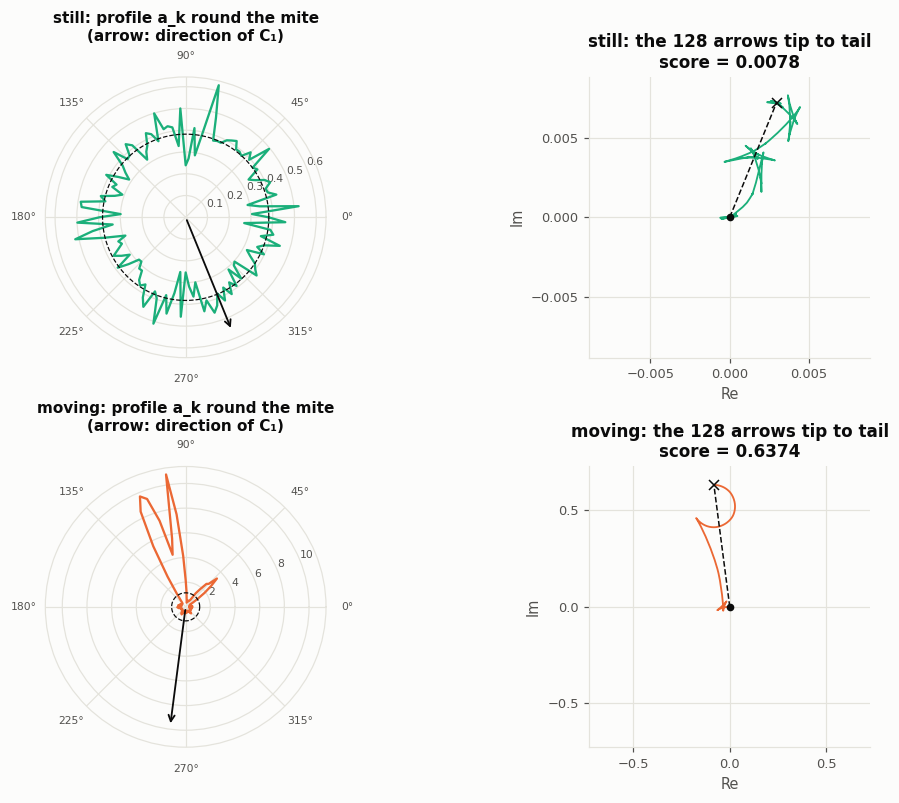

In [2]:
poke = (data["dataset"] == "poke_test_oct").to_numpy()

def median_of(mask):
    candidates = np.nonzero(mask)[0]
    return candidates[np.argsort(data["score"].to_numpy()[candidates])][len(candidates) // 2]

def walk(index):
    return np.concatenate([[0], np.cumsum(eps[index] * STEP / K)])

fig = plt.figure(figsize=(10, 7.4))
for row, (mask, color, label) in enumerate([(poke & still, AQUA, "still"), (poke & moving, ORANGE, "moving")]):
    i = median_of(mask)
    ax = fig.add_subplot(2, 2, 2 * row + 1, projection="polar")
    closed = np.append(THETA, THETA[0])
    ax.plot(closed, np.append(P[i], P[i][0]), color=color, linewidth=1.5)
    ax.plot(closed, np.full(K + 1, P[i].mean()), color=INK, linestyle="--", linewidth=0.8)
    ax.annotate("", xy=(np.angle(CC[i, 1]), P[i].max() * 0.9), xytext=(0, 0),
                arrowprops={"arrowstyle": "->", "color": INK, "linewidth": 1.2})
    ax.set_title(f"{label}: profile a_k round the mite\n(arrow: direction of C₁)", fontsize=10)
    ax.tick_params(labelsize=7)
    ax = fig.add_subplot(2, 2, 2 * row + 2)
    w = walk(i)
    ax.plot(w.real, w.imag, color=color, linewidth=1.2)
    ax.plot([0, w[-1].real], [0, w[-1].imag], color=INK, linestyle="--", linewidth=1)
    ax.plot(0, 0, "o", color=INK, markersize=4)
    ax.plot(w[-1].real, w[-1].imag, "x", color=INK, markersize=7)
    span = max(np.abs(w.real).max(), np.abs(w.imag).max()) * 1.15
    ax.set(xlim=(-span, span), ylim=(-span, span), aspect="equal", xlabel="Re", ylabel="Im",
           title=f"{label}: the 128 arrows tip to tail\nscore = {data['score'].iat[i]:.4f}")
    ax.locator_params(nbins=4)
plt.tight_layout()
plt.show()

The still profile is nearly a circle, with small wiggles all round; its arrows wander and end close to where they started. The moving profile bulges on the side of the moving leg, and its arrows march off that way. More recordings, at the 25th, 50th and 75th percentile of each group's score:

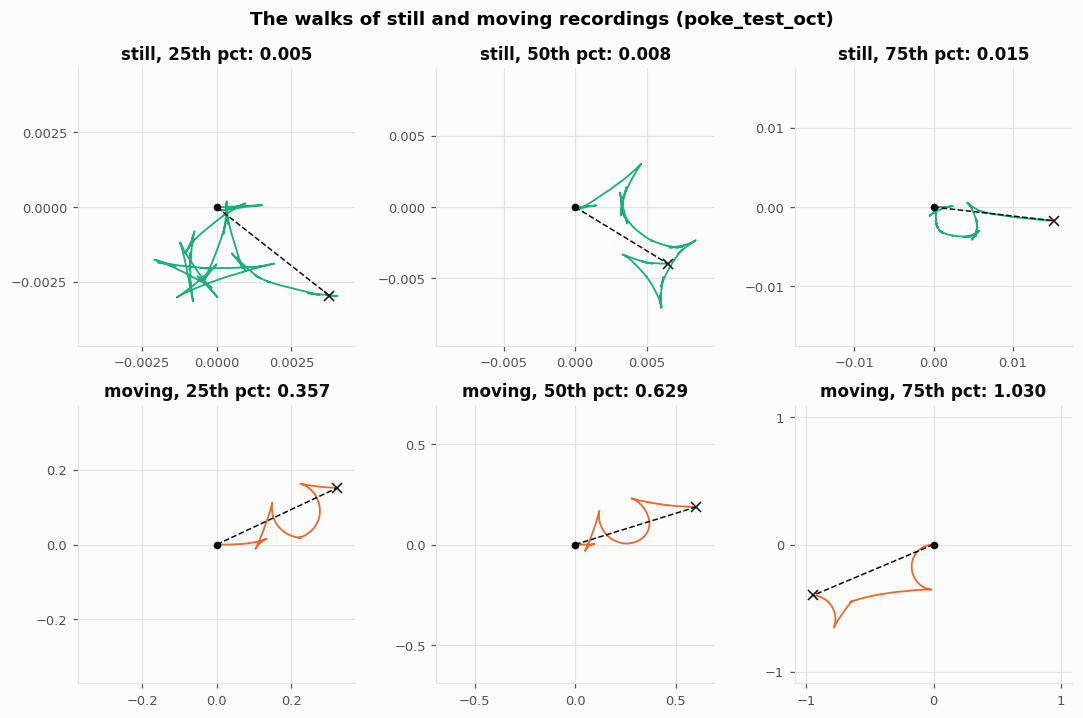

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6.6))
for row, (mask, color, label) in enumerate([(poke & still, AQUA, "still"), (poke & moving, ORANGE, "moving")]):
    candidates = np.nonzero(mask)[0]
    order = candidates[np.argsort(data["score"].to_numpy()[candidates])]
    for ax, q in zip(axes[row], (0.25, 0.5, 0.75)):
        i = order[int(q * (len(order) - 1))]
        w = walk(i)
        ax.plot(w.real, w.imag, color=color, linewidth=1.2)
        ax.plot([0, w[-1].real], [0, w[-1].imag], color=INK, linestyle="--", linewidth=1)
        ax.plot(0, 0, "o", color=INK, markersize=4)
        ax.plot(w[-1].real, w[-1].imag, "x", color=INK, markersize=7)
        span = max(np.abs(w.real).max(), np.abs(w.imag).max()) * 1.15
        ax.set(xlim=(-span, span), ylim=(-span, span), aspect="equal",
               title=f"{label}, {int(q * 100)}th pct: {data['score'].iat[i]:.3f}")
        ax.locator_params(nbins=4)
fig.suptitle("The walks of still and moving recordings (poke_test_oct)", fontweight="bold")
plt.tight_layout()
plt.show()

## Step 2. What the theory predicts

If the $\varepsilon_k$ are independent noise with standard deviation $\tau$, $C_1$ is the end of a random walk of 128 steps. The central limit theorem then gives:

- the end point $C_1$ is a **round 2-D Gaussian** centred on 0, with variance $\sigma^2 = \tau^2 / 2K$ along each axis;
- the score $|C_1|$, its distance from 0, follows a **Rayleigh distribution** with scale $\sigma$: density $\frac{r}{\sigma^2} e^{-r^2/2\sigma^2}$, median $1.18\,\sigma$, 90th percentile $2.15\,\sigma$, 99th percentile $3.03\,\sigma$;
- the walk's squared distance from the start grows in proportion to the number of steps, as in Brownian motion.

The Rayleigh distribution has one parameter, the **scale** $\sigma$: it sets how large the scores are and leaves the shape alone. So the test is always: divide each score by its σ, and see whether the results follow the standard Rayleigh shape (σ = 1).

Here is the theory simulated: 20,000 walks of 128 independent Gaussian steps, each in its direction $\theta_k$.

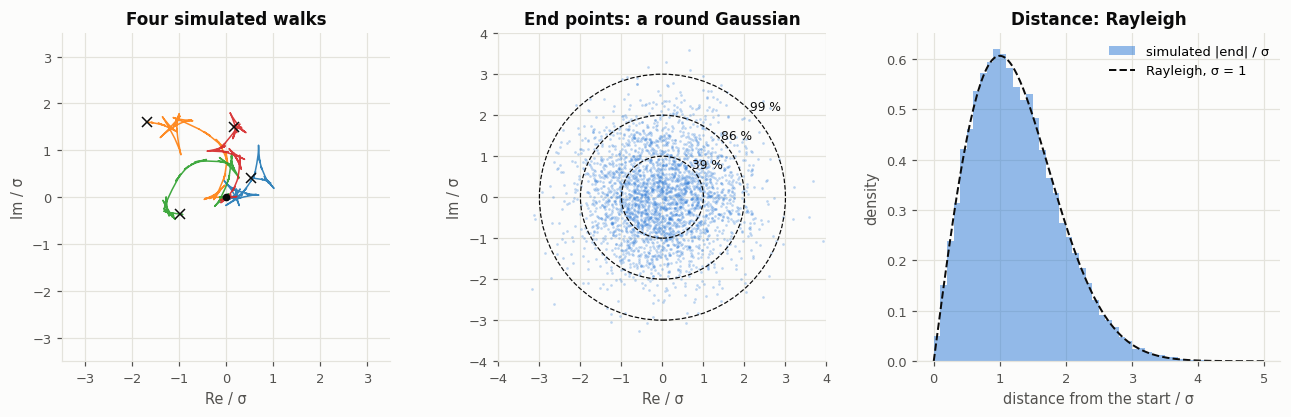

In [4]:
sim_steps = rng.normal(size=(20_000, K))
sim_end = (sim_steps * STEP).mean(axis=1)
sim_sigma = 1 / np.sqrt(2 * K)                   # tau = 1

fig, axes = plt.subplots(1, 3, figsize=(12, 3.9))
for j in range(4):
    w = np.concatenate([[0], np.cumsum(sim_steps[j] * STEP / K)])
    axes[0].plot(w.real / sim_sigma, w.imag / sim_sigma, linewidth=1, alpha=0.9)
    axes[0].plot(w[-1].real / sim_sigma, w[-1].imag / sim_sigma, "x", color=INK, markersize=6)
axes[0].plot(0, 0, "o", color=INK, markersize=4)
axes[0].set(aspect="equal", xlim=(-3.5, 3.5), ylim=(-3.5, 3.5), xlabel="Re / σ", ylabel="Im / σ", title="Four simulated walks")

axes[1].scatter(sim_end.real[:3000] / sim_sigma, sim_end.imag[:3000] / sim_sigma, s=3, color=BLUE, alpha=0.3, linewidth=0)
for r, share in ((1, 39), (2, 86), (3, 99)):
    axes[1].add_patch(plt.Circle((0, 0), r, fill=False, color=INK, linestyle="--", linewidth=0.8))
    axes[1].annotate(f"{share} %", (r * 0.71, r * 0.71), fontsize=8, color=INK)
axes[1].set(aspect="equal", xlim=(-4, 4), ylim=(-4, 4), xlabel="Re / σ", ylabel="Im / σ", title="End points: a round Gaussian")

x = np.linspace(0, 5, 200)
axes[2].hist(np.abs(sim_end) / sim_sigma, np.linspace(0, 5, 51), density=True, color=BLUE, alpha=0.5, label="simulated |end| / σ")
axes[2].plot(x, stats.rayleigh.pdf(x), color=INK, linestyle="--", linewidth=1.3, label="Rayleigh, σ = 1")
axes[2].set(xlabel="distance from the start / σ", ylabel="density", title="Distance: Rayleigh")
axes[2].legend()
plt.tight_layout()
plt.show()

The circles hold 39 %, 86 % and 99 % of the end points, as a 2-D Gaussian does at 1, 2 and 3 σ. Steps 3 to 13 hold the real recordings against these pictures.

## Step 3. Does the real walk spread like a random walk?

For a random walk with independent steps, the mean squared distance from the start after $n$ steps grows as $n$: a straight line of slope 1 on log-log axes. A walk that keeps heading one way (past a moving leg) grows as $n^2$. The distance is averaged over all 128 starting rays of each recording, then over the recordings, and divided by its value after one step.

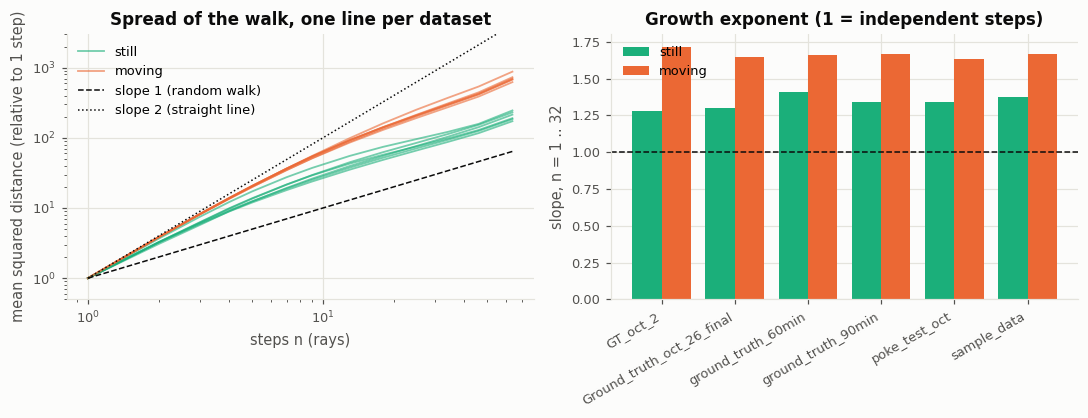

,still,moving
GT_oct_2,1.28,1.72
Ground_truth_oct_26_final,1.30,1.65
ground_truth_60min,1.41,1.66
ground_truth_90min,1.34,1.67
poke_test_oct,1.34,1.63
sample_data,1.38,1.67


In [5]:
lags = np.unique(np.round(np.geomspace(1, K // 2, 14)).astype(int))

def spread(rows):
    out = np.zeros(len(lags))
    for start in range(K):
        path = np.cumsum(np.roll(eps[rows] * STEP, -start, axis=1), axis=1)
        out += (np.abs(path[:, lags - 1]) ** 2).mean(axis=0)
    return out / out[0]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
slopes = {}
for name in DATASETS:
    in_set = (data["dataset"] == name).to_numpy()
    for mask, color, label in [(still, AQUA, "still"), (moving, ORANGE, "moving")]:
        msd = spread(in_set & mask)
        slopes[(name, label)] = np.polyfit(np.log(lags[lags <= 32]), np.log(msd[lags <= 32]), 1)[0]
        axes[0].plot(lags, msd, color=color, alpha=0.6, linewidth=1.2, label=label if name == DATASETS[0] else None)
axes[0].plot(lags, lags, color=INK, linestyle="--", linewidth=1, label="slope 1 (random walk)")
axes[0].plot(lags, lags ** 2.0, color=INK, linestyle=":", linewidth=1, label="slope 2 (straight line)")
axes[0].set(xscale="log", yscale="log", xlabel="steps n (rays)", ylabel="mean squared distance (relative to 1 step)",
            title="Spread of the walk, one line per dataset", ylim=(0.5, 3e3))
axes[0].legend()

table = pd.Series(slopes).unstack()[["still", "moving"]]
x = np.arange(len(table))
axes[1].bar(x - 0.2, table["still"], 0.4, color=AQUA, label="still")
axes[1].bar(x + 0.2, table["moving"], 0.4, color=ORANGE, label="moving")
axes[1].axhline(1, color=INK, linestyle="--", linewidth=1)
axes[1].set(xticks=x, ylabel="slope, n = 1 .. 32", title="Growth exponent (1 = independent steps)")
axes[1].set_xticklabels(table.index, rotation=30, ha="right")
axes[1].legend()
plt.tight_layout()
plt.show()
display(table.round(2))

Still walks grow with an exponent of about 1.3 to 1.4, moving ones with about 1.65. Still walks are much closer to a random walk than moving ones, but not exactly one with independent steps. Averaged over every starting ray like this, the spread depends only on how the steps are correlated with each other, so step 4 looks at that correlation directly.

## Step 4. Are the steps independent?

Left: the correlation of $\varepsilon_k$ with $\varepsilon_{k+\ell}$, the step $\ell$ rays further round. Right: the same in harmonics, the median of $|C_h|^2$ over still recordings, divided by what independent steps give at every harmonic ($\tau^2/K$). Independent steps would be a flat line at 1.

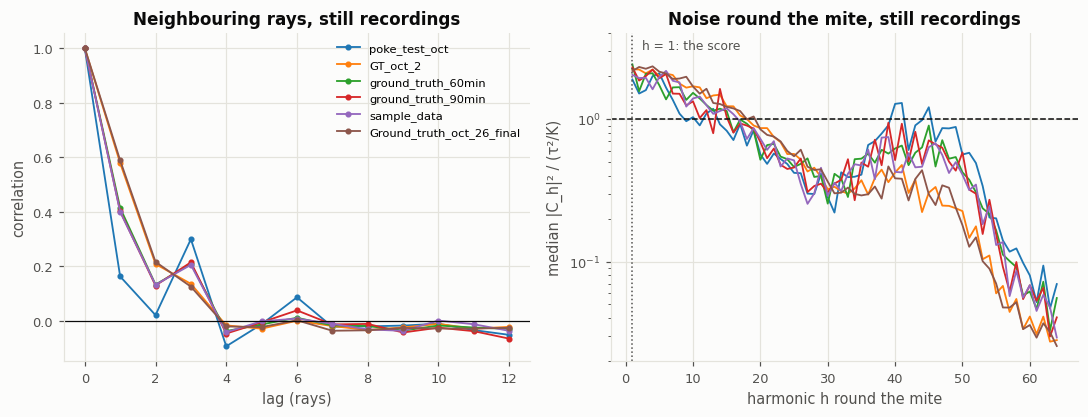

In [6]:
def autocorrelation(rows):
    power = np.abs(np.fft.rfft(eps[rows], axis=1)) ** 2
    ac = np.fft.irfft(power, n=K, axis=1)
    return np.median(ac / ac[:, :1], axis=0)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
for name in DATASETS:
    in_set = (data["dataset"] == name).to_numpy() & still
    axes[0].plot(np.arange(13), autocorrelation(in_set)[:13], marker="o", markersize=3, linewidth=1.2, label=name)
    white = (data["tau"].to_numpy()[in_set] ** 2 / K)[:, None]
    axes[1].plot(np.arange(1, 65), np.median(np.abs(CC[in_set, 1:]) ** 2 / white, axis=0), linewidth=1.2, label=name)
axes[0].axhline(0, color=INK, linewidth=0.8)
axes[0].set(xlabel="lag (rays)", ylabel="correlation", title="Neighbouring rays, still recordings")
axes[0].legend(fontsize=7.5)
axes[1].axhline(1, color=INK, linestyle="--", linewidth=1, label="independent steps")
axes[1].axvline(1, color=MUTED, linestyle=":", linewidth=1)
axes[1].annotate("h = 1: the score", (1, 3.1), xytext=(6, 0), textcoords="offset points", fontsize=8, color=MUTED)
axes[1].set(yscale="log", xlabel="harmonic h round the mite", ylabel="median |C_h|² / (τ²/K)",
            title="Noise round the mite, still recordings", ylim=(0.02, 4))
plt.tight_layout()
plt.show()

The steps are **not** independent. Rays next to each other are about 1 px apart on the outline and read overlapping pixels, so their noise is correlated over one or two rays (in `poke_test_oct` again at 3 rays, from the pattern in which the rays sample the pixel grid; every dataset has a bump near $h = 128/3 \approx 43$). In harmonics, the noise is about twice as strong at $h = 1$ as independent steps would make it.

Correlation over a few rays doesn't break the random walk. The central limit theorem holds for steps correlated over a short range, so the end point is still Gaussian and the score still Rayleigh. What changes is the **scale**: it is no longer $\tau/\sqrt{2K}$. Dividing the still scores by that formula shows the effect: the shape looks right, but it sits too far to the right.

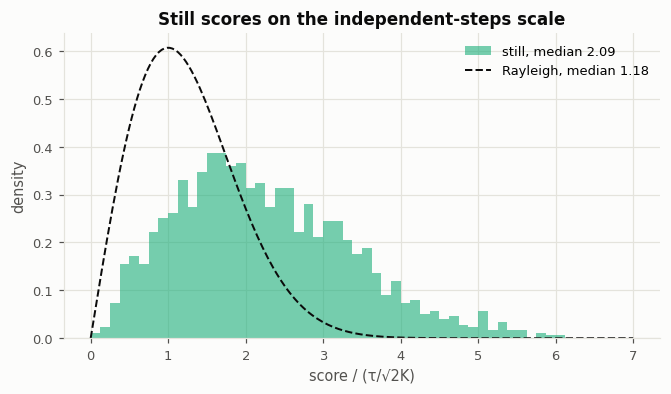

In [7]:
z_white = (data["score"] / data["sigma_white"]).to_numpy()
fig, ax = plt.subplots(figsize=(7, 3.6))
bins = np.linspace(0, 7, 57)
x = np.linspace(0, 7, 200)
ax.hist(z_white[still], bins, density=True, color=AQUA, alpha=0.6, label=f"still, median {np.median(z_white[still]):.2f}")
ax.plot(x, stats.rayleigh.pdf(x), color=INK, linestyle="--", linewidth=1.3, label="Rayleigh, median 1.18")
ax.set(xlabel="score / (τ/√2K)", ylabel="density", title="Still scores on the independent-steps scale")
ax.legend()
plt.show()

About 1.8 times too large. σ has to be **measured**, not computed from τ. Steps 5 and 6 find a way to measure it that a moving leg doesn't spoil.

## Step 5. Is the noise white over the frames?

The variance on each ray is a sum over the frames' frequencies $f$ (Parseval's theorem), so harmonic 1 is too: $C_1 = \sum_f C[f, 1]$. If a still outline only carries the camera's noise, independent from frame to frame, that noise is **white**: every frequency $f$ holds the same power. If the pixels drifted like Brownian motion *over the frames*, the power would fall as $1/f^2$. A moving leg changes slowly compared with the camera's noise, so it puts its power at low $f$.

Below, for the three recording lengths, the power at each frame frequency relative to the recording's own level in the upper half of the frequencies (the shaded band), the median over the recordings. On this scale white noise is 1 at every $f$. Two things are drawn for still recordings: the power **all round** the mite ($h = 0$, the mean of the variance round the outline), and the power **at $h = 1$** (the one-sided part, which the score adds up). The noise's power at one frequency and harmonic is exponentially distributed, with a median of ln 2 ≈ 0.69 times its mean, so the medians at $h = 1$ are divided by ln 2 to put white noise at 1.

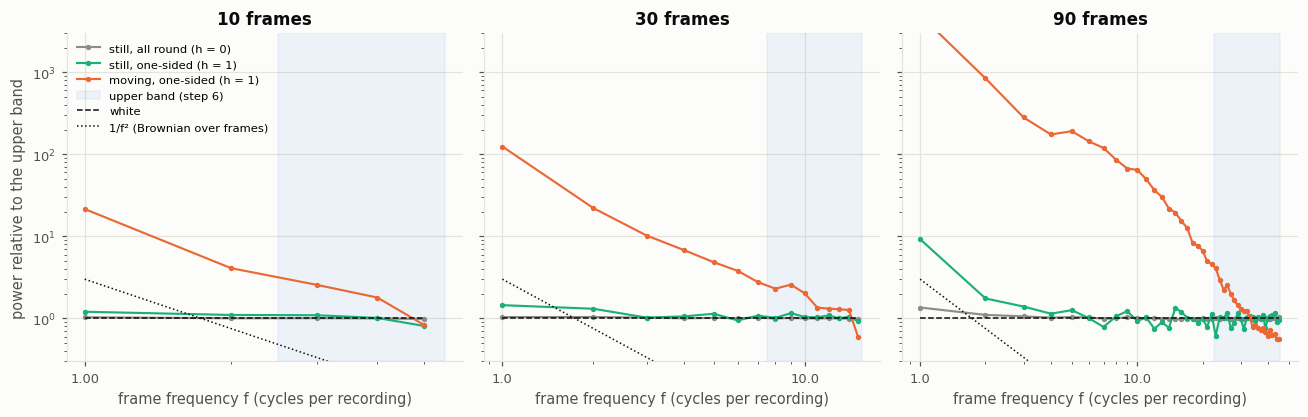

f = 1  f = 2  f = 3
frames                                  
10     still, h = 0   1.03   1.00   1.00
       still, h = 1   1.20   1.10   1.09
30     still, h = 0   1.04   1.04   1.02
       still, h = 1   1.45   1.31   1.02
90     still, h = 0   1.35   1.10   1.06
       still, h = 1   9.22   1.75   1.39

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.9), sharey=True)
for ax, frames in zip(axes, (10, 30, 90)):
    names = [n for n in DATASETS if data.loc[data["dataset"] == n, "frames"].iat[0] == frames]
    h1 = np.concatenate([spectra[n]["h1"] for n in names])
    h0 = np.concatenate([spectra[n]["h0"] for n in names])
    rows = np.concatenate([(~data.loc[data["dataset"] == n, "moving"]).to_numpy() for n in names])
    f = np.arange(1, h1.shape[1] + 1)
    ax.plot(f, np.median(h0[rows], axis=0), color=GREY, marker="o", markersize=2.5, linewidth=1.4, label="still, all round (h = 0)")
    ax.plot(f, np.median(h1[rows], axis=0) / LN2, color=AQUA, marker="o", markersize=2.5, linewidth=1.4, label="still, one-sided (h = 1)")
    ax.plot(f, np.median(h1[~rows], axis=0) / LN2, color=ORANGE, marker="o", markersize=2.5, linewidth=1.4, label="moving, one-sided (h = 1)")
    ax.axvspan(f[len(f) // 2] - 0.5, f[-1] + 0.5, color=BLUE, alpha=0.07, label="upper band (step 6)")
    ax.plot(f, np.ones_like(f, dtype=float), color=INK, linestyle="--", linewidth=1, label="white")
    ax.plot(f, 3 * (f / f[0]) ** -2.0, color=INK, linestyle=":", linewidth=1, label="1/f² (Brownian over frames)")
    ax.set(xscale="log", yscale="log", ylim=(0.3, 3000), xlabel="frame frequency f (cycles per recording)", title=f"{frames} frames")
    ax.xaxis.set_major_formatter(plt.ScalarFormatter())
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
axes[0].set_ylabel("power relative to the upper band")
axes[0].legend(fontsize=7.5)
plt.tight_layout()
plt.show()

table = {}
for frames in (10, 30, 90):
    names = [n for n in DATASETS if data.loc[data["dataset"] == n, "frames"].iat[0] == frames]
    rows = np.concatenate([(~data.loc[data["dataset"] == n, "moving"]).to_numpy() for n in names])
    for key, label, scale in (("h0", "still, h = 0", 1), ("h1", "still, h = 1", LN2)):
        values = np.concatenate([spectra[n][key] for n in names])[rows]
        table[(frames, label)] = {"f = 1": np.median(values[:, 0]) / scale, "f = 2": np.median(values[:, 1]) / scale,
                                  "f = 3": np.median(values[:, 2]) / scale}
display(pd.DataFrame(table).T.round(2).rename_axis(["frames", ""]))

- **All round the mite ($h = 0$) the noise is white**: flat at 1 in every recording length, never close to $1/f^2$. The camera's noise is independent from frame to frame, so the outline's pixels don't drift like Brownian motion over the frames. "Brownian" in this notebook means the walk *round the mite* only.
- **The one-sided part ($h = 1$) of still recordings is white at high frequencies but rises at the lowest ones, the more the longer the recording**: about 1.2 times the noise level at $f = 1$ in 10-frame recordings, 1.45 in 30-frame ones, and 9 times in 90-frame ones (one slow swing over the 3 s). Something on one side of a still mite changes slowly during the recording. The score adds up all frequencies, so it carries that slow part as well as the noise.
- **Moving recordings** rise hundreds of times at low $f$: a leg moves slowly compared with the camera's noise.

So the random-walk theory applies to the white part. Step 6 measures that part's scale where the slow part doesn't reach, and step 9 comes back to the slow part.

## Step 6. A scale from the noise alone

White noise holds the same power at every frame frequency. So the noise's power at $h = 1$ can be measured where a slow change hardly reaches, **the upper half of the frame frequencies** (the shaded band above), and scaled up to all of them:

$$\sigma^2 = \tfrac12 \cdot F \cdot \overline{|C[f, h]|^2}_{\,f \text{ in the upper half},\; h = 1..5}$$

$F$ is the number of frame frequencies ($N/2$ for $N$ frames, the Nyquist term counting half), and the ½ splits the power over the two axes of the end point. $h = 2 \dots 5$ are averaged in with $h = 1$ so that even a 10-frame recording has 10 noise values to average. Nothing in this σ comes from the score itself.

Because σ is itself estimated from a few values, score / σ follows the Rayleigh shape divided by the estimate's own error. The notebook simulates that exactly ("theory" in the figures below). With 10 values it is a little wider than Rayleigh; with 35 or 110 values it is Rayleigh.

On the left, the band in two recordings of `poke_test_oct`. On the right, why this σ and not another: when a mite moves the score rises a lot, and a scale meant to measure the noise should rise as little as possible with it.

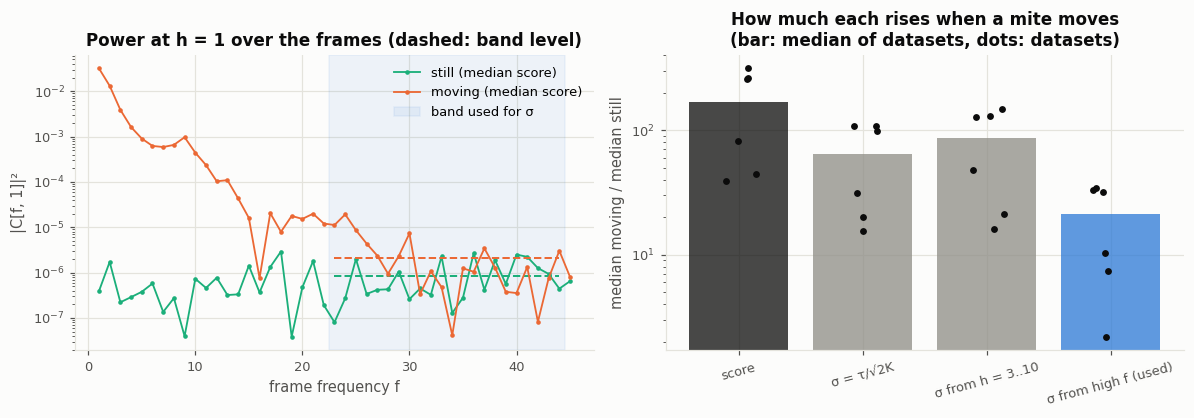

,score,σ = τ/√2K,σ from h = 3..10,σ from high f (used)
poke_test_oct,82.1,31.1,47.6,2.2
GT_oct_2,39.0,15.6,16.0,7.4
ground_truth_60min,263.9,107.9,146.5,34.5
ground_truth_90min,313.1,107.1,129.1,33.0
sample_data,256.4,98.2,126.4,31.7
Ground_truth_oct_26_final,44.5,19.9,21.3,10.4


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
for mask, color, label in [(poke & still, AQUA, "still"), (poke & moving, ORANGE, "moving")]:
    i = median_of(mask)
    local = i - np.nonzero(poke)[0][0]
    power = np.abs(spectra["poke_test_oct"]["S"][local, :, 1]) ** 2
    f = np.arange(1, len(power) + 1)
    axes[0].plot(f, power, color=color, linewidth=1.2, marker="o", markersize=2, label=f"{label} (median score)")
    level = data["sigma_noise"].iat[i] ** 2 * 2 / (len(f) - 0.5)
    axes[0].hlines(level, f[len(f) // 2], f[-2], color=color, linestyle="--", linewidth=1.3)
axes[0].axvspan(f[len(f) // 2] - 0.5, f[-1] - 0.5, color=BLUE, alpha=0.07, label="band used for σ")
axes[0].set(yscale="log", xlabel="frame frequency f", ylabel="|C[f, 1]|²",
            title="Power at h = 1 over the frames (dashed: band level)")
axes[0].legend()

measures = {"score": "score", "σ = τ/√2K": "sigma_white", "σ from h = 3..10": "sigma_near", "σ from high f (used)": "sigma_noise"}
ratios = pd.DataFrame({label: [data.loc[(data["dataset"] == n) & data["moving"], column].median()
                               / data.loc[(data["dataset"] == n) & ~data["moving"], column].median() for n in DATASETS]
                       for label, column in measures.items()}, index=DATASETS)
x = np.arange(len(measures))
colors = [INK, GREY, GREY, BLUE]
axes[1].bar(x, ratios.median(), color=colors, alpha=0.75)
for j, column in enumerate(ratios):
    axes[1].scatter(np.full(len(ratios), j) + rng.uniform(-0.15, 0.15, len(ratios)), ratios[column], s=12, color=INK, zorder=3)
axes[1].set(yscale="log", xticks=x, ylabel="median moving / median still",
            title="How much each rises when a mite moves\n(bar: median of datasets, dots: datasets)")
axes[1].set_xticklabels(measures, rotation=15)
plt.tight_layout()
plt.show()
display(ratios.round(1))

The two σ taken from the whole profile rise about half as much as the score when a mite moves (median over datasets: 60 to 90 times against 170), because a moving leg raises the whole profile. Dividing by them cancels most of the difference between moving and still, so they can't tell a leg from noise. The σ from the high frame frequencies rises less (about 20 times; only 2 times in `poke_test_oct`, about 30 in the 30-frame datasets, whose fast legs reach the upper band too). It is not perfect, but its rise is the smallest of the three, and score / σ still separates moving from still well (step 13).

For still recordings, which this notebook tests, the leg's effect doesn't matter. What matters is that this σ comes from the white part only, so it cannot absorb a slow change the way the other two do.

## Step 7. Is the end point a round 2-D Gaussian?

$C_1/\sigma$ of every still recording as a point in the plane, with the circles at 1, 2 and 3 of step 2. Then the two coordinates one by one against the theory's quantiles (simulated with each recording's number of noise values): on the dashed diagonal if they are Gaussian.

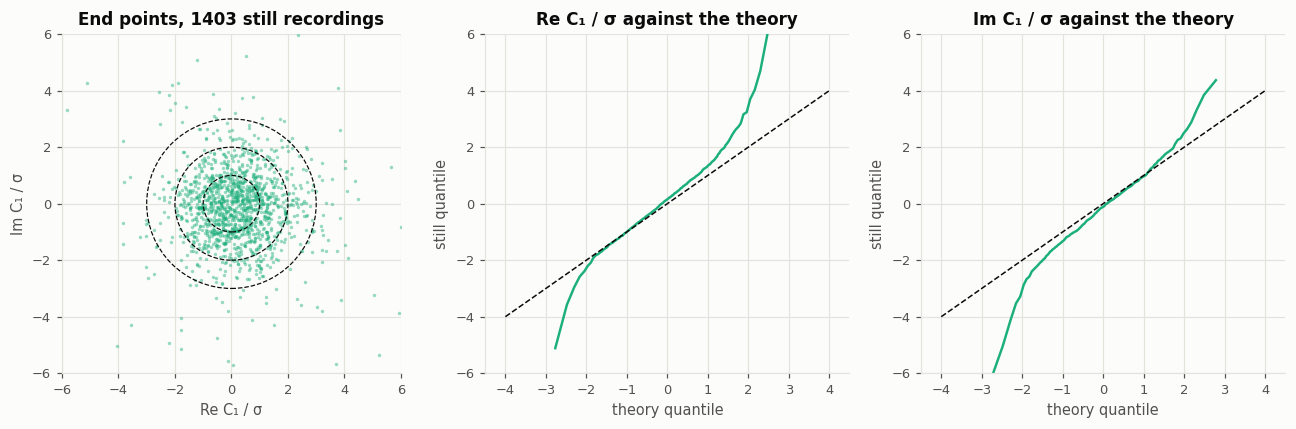

,within 1,within 2,within 3
still recordings,31.2 %,74.4 %,90.2 %
theory,39.1 %,84.4 %,97.9 %


In [10]:
c1 = CC[:, 1] / data["sigma_noise"].to_numpy()
null_c1 = np.concatenate([(rng.normal(size=50 * c) + 1j * rng.normal(size=50 * c))
                          / np.sqrt(rng.chisquare(2 * m, 50 * c) / (2 * m))
                          for m, c in data.loc[still, "noise_values"].value_counts().items()])

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].scatter(c1[still].real, c1[still].imag, s=5, color=AQUA, alpha=0.45, linewidth=0)
for r in (1, 2, 3):
    axes[0].add_patch(plt.Circle((0, 0), r, fill=False, color=INK, linestyle="--", linewidth=0.8))
axes[0].set(xlim=(-6, 6), ylim=(-6, 6), aspect="equal", xlabel="Re C₁ / σ", ylabel="Im C₁ / σ",
            title=f"End points, {still.sum()} still recordings")
q = np.linspace(0.005, 0.995, 199)
for ax, part, label in [(axes[1], np.real, "Re"), (axes[2], np.imag, "Im")]:
    ax.plot(np.quantile(part(null_c1), q), np.quantile(part(c1[still]), q), color=AQUA, linewidth=1.6)
    ax.plot([-4, 4], [-4, 4], color=INK, linestyle="--", linewidth=1)
    ax.set(xlim=(-4.5, 4.5), ylim=(-6, 6), xlabel="theory quantile", ylabel="still quantile", title=f"{label} C₁ / σ against the theory")
plt.tight_layout()
plt.show()

inside = pd.DataFrame({f"within {r}": {"still recordings": (np.abs(c1[still]) <= r).mean(), "theory": (np.abs(null_c1) <= r).mean()}
                       for r in (1, 2, 3)})
display((100 * inside).round(1).astype(str) + " %")

The core of the cloud is round and centred on 0, and both coordinates follow the theory between about −2 and +2. Outside that, the still recordings have tails the theory doesn't: 10 % fall outside the circle at 3, against 2 % for noise. Those are the high still scores of step 9. (Re leans to the right a little: step 11 shows that still arrows prefer one direction in the image.)

## Step 8. Is score / σ Rayleigh-distributed?

The score of each still recording divided by its own σ from step 6, against the theory: the Rayleigh shape, widened a little for the estimate of σ (dashed). One panel per recording length.

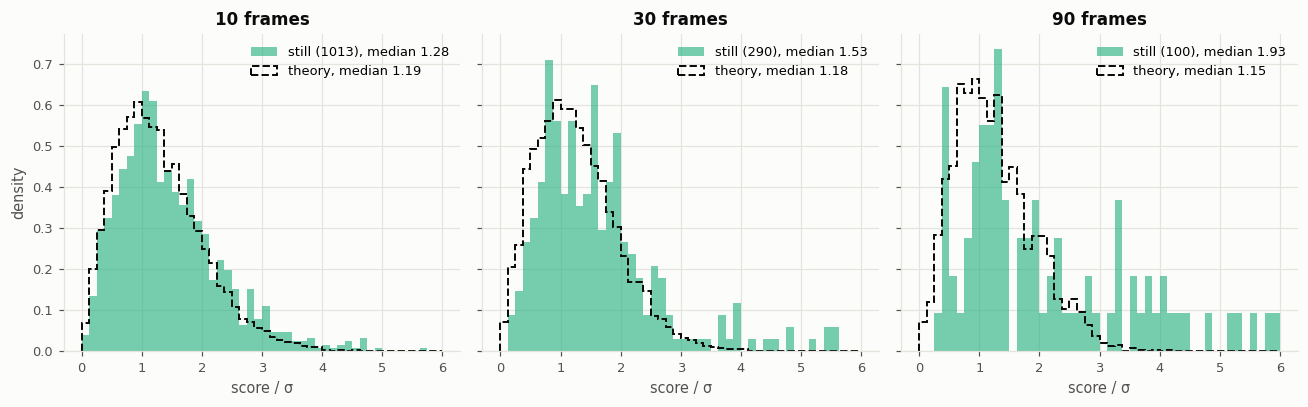

In [11]:
z = data["z"].to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
bins = np.linspace(0, 6, 49)
for ax, frames in zip(axes, (10, 30, 90)):
    rows = still & (data["frames"] == frames).to_numpy()
    theory = np.concatenate([NULL[n][: 20 * (rows & (data["dataset"] == n).to_numpy()).sum()] for n in DATASETS])
    ax.hist(z[rows], bins, density=True, color=AQUA, alpha=0.6, label=f"still ({rows.sum()}), median {np.median(z[rows]):.2f}")
    ax.hist(theory, bins, density=True, histtype="step", color=INK, linestyle="--", linewidth=1.3,
            label=f"theory, median {np.median(theory):.2f}")
    ax.set(xlabel="score / σ", title=f"{frames} frames")
    ax.legend()
axes[0].set_ylabel("density")
plt.tight_layout()
plt.show()

The bulk follows the theory in all three lengths. A quantile plot per dataset shows where they part: on the diagonal while they agree, bending up where still recordings have more high values than noise gives.

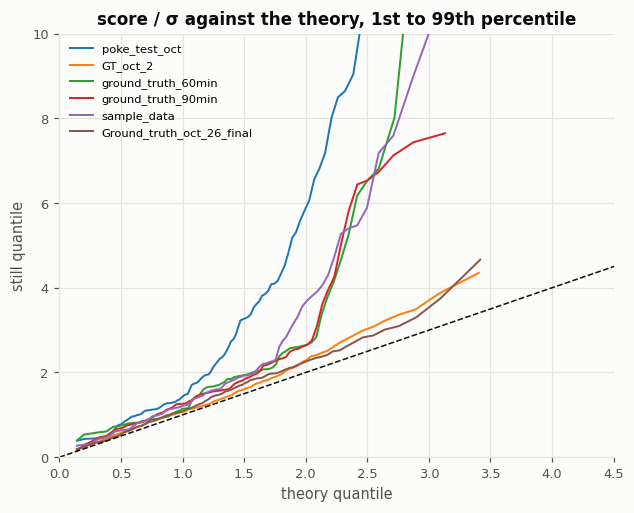

,frames,still,q10 measured,median measured,q90 measured,q99 measured,q10 theory,median theory,q90 theory,q99 theory
dataset,,,,,,,,,,
poke_test_oct,90,100,0.71,1.93,7.18,12.07,0.46,1.18,2.16,3.06
GT_oct_2,10,478,0.54,1.24,2.71,4.35,0.46,1.20,2.28,3.41
ground_truth_60min,30,96,0.73,1.63,3.77,16.29,0.46,1.18,2.18,3.15
ground_truth_90min,30,97,0.66,1.51,3.94,7.65,0.46,1.18,2.18,3.13
sample_data,30,97,0.62,1.51,4.30,11.07,0.46,1.18,2.18,3.13
Ground_truth_oct_26_final,10,535,0.48,1.35,2.52,4.66,0.46,1.20,2.27,3.42


In [12]:
fig, ax = plt.subplots(figsize=(6.5, 5))
q = np.linspace(0.01, 0.99, 99)
for name in DATASETS:
    rows = still & (data["dataset"] == name).to_numpy()
    ax.plot(np.quantile(NULL[name], q), np.quantile(z[rows], q), linewidth=1.3, label=name)
ax.plot([0, 6], [0, 6], color=INK, linestyle="--", linewidth=1)
ax.set(xlim=(0, 4.5), ylim=(0, 10), xlabel="theory quantile", ylabel="still quantile", title="score / σ against the theory, 1st to 99th percentile")
ax.legend(fontsize=7.5)
plt.show()

table = []
for name in DATASETS:
    rows = still & (data["dataset"] == name).to_numpy()
    measured, theory = np.quantile(z[rows], [0.1, 0.5, 0.9, 0.99]), np.quantile(NULL[name], [0.1, 0.5, 0.9, 0.99])
    table.append({"dataset": name, "frames": data.loc[rows, "frames"].iat[0], "still": rows.sum(),
                  **{f"{p} measured": m for p, m in zip(("q10", "median", "q90", "q99"), measured)},
                  **{f"{p} theory": t for p, t in zip(("q10", "median", "q90", "q99"), theory)}})
display(pd.DataFrame(table).set_index("dataset").round(2))

The lower half follows the theory in every dataset (10th percentile 0.5 to 0.7 against 0.46). In the 10-frame datasets the median and 90th percentile are close too (1.24 to 1.35 against 1.20, and 2.5 to 2.7 against 2.3). The 30- and 90-frame datasets have a tail that noise doesn't make: their 90th percentile is 3.8 to 7.2 against 2.2, and the 90-frame median is already 1.9. The next step shows what that tail is.

## Step 9. Where the high still scores come from: slow change

Noise spreads its power at $h = 1$ evenly over the frame frequencies, so about 20 % of it falls in the lowest fifth of them (the dashed line below; for 10 frames the lowest fifth is $f = 1$ alone). A one-sided change that builds up slowly during the recording (a leg creeping, the body settling, a neighbour approaching, a shift the stabiliser left over) puts its power there instead. Left: every still recording's score / σ against that share. Recordings with at least twice noise's share are marked **slow change**.

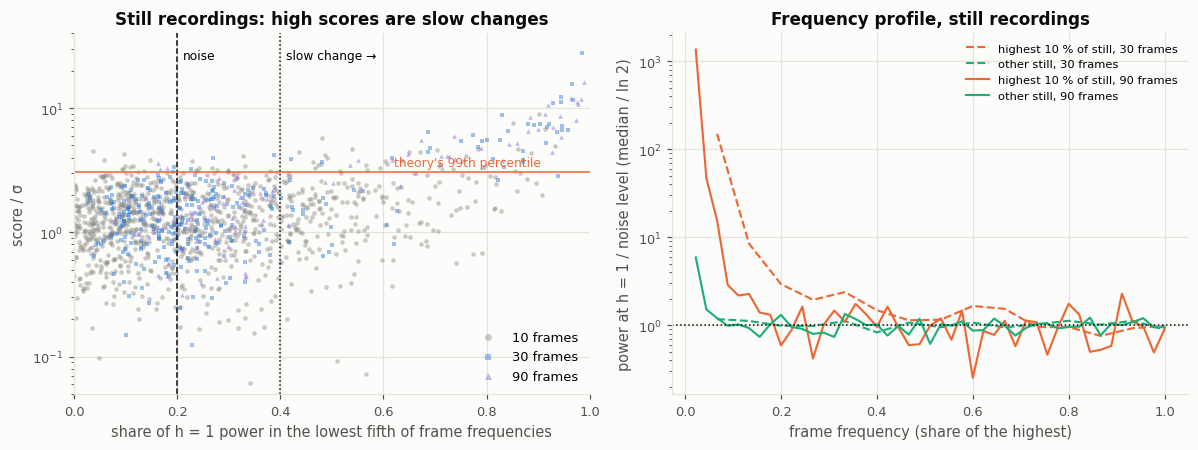

,frames,still with slow change,still above theory's 99th pct,"of those, slow change"
dataset,,,,
poke_test_oct,90,0.36,0.35,0.89
GT_oct_2,10,0.15,0.04,0.67
ground_truth_60min,30,0.15,0.11,1.00
ground_truth_90min,30,0.19,0.12,0.92
sample_data,30,0.24,0.18,0.82
Ground_truth_oct_26_final,10,0.19,0.03,0.87


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for frames, marker in ((10, "o"), (30, "s"), (90, "^")):
    rows = still & (data["frames"] == frames).to_numpy()
    axes[0].scatter(data["slow_share"][rows], z[rows], s=9, marker=marker, alpha=0.45, linewidth=0,
                    color={10: GREY, 30: BLUE, 90: PURPLE}[frames], label=f"{frames} frames")
axes[0].axvline(0.2, color=INK, linestyle="--", linewidth=1)
axes[0].axvline(0.4, color=INK, linestyle=":", linewidth=1)
axes[0].axhline(np.quantile(NULL["poke_test_oct"], 0.99), color=ORANGE, linewidth=1)
axes[0].annotate("noise", (0.2, 25), xytext=(4, 0), textcoords="offset points", fontsize=8)
axes[0].annotate("slow change →", (0.4, 25), xytext=(4, 0), textcoords="offset points", fontsize=8)
axes[0].annotate("theory's 99th percentile", (0.62, np.quantile(NULL["poke_test_oct"], 0.99)), xytext=(0, 4),
                 textcoords="offset points", fontsize=8, color=ORANGE)
axes[0].set(yscale="log", xlim=(0, 1), ylim=(0.05, 40), xlabel="share of h = 1 power in the lowest fifth of frame frequencies",
            ylabel="score / σ", title="Still recordings: high scores are slow changes")
axes[0].legend(loc="lower right", markerscale=1.5)

# the frequency profile of the highest still scores against the others, 30- and 90-frame recordings
for frames, style in ((30, "--"), (90, "-")):
    names = [n for n in DATASETS if data.loc[data["dataset"] == n, "frames"].iat[0] == frames]
    relative = np.concatenate([spectra[n]["h1"] for n in names])
    in_len = (data["frames"] == frames).to_numpy()
    rows_still = still[in_len]
    zz = z[in_len]
    top = rows_still & (zz >= np.quantile(zz[rows_still], 0.9))
    rest = rows_still & ~top
    f = np.arange(1, relative.shape[1] + 1)
    axes[1].plot(f / f[-1], np.median(relative[top], axis=0) / LN2, color=ORANGE, linestyle=style, linewidth=1.4,
                 label=f"highest 10 % of still, {frames} frames")
    axes[1].plot(f / f[-1], np.median(relative[rest], axis=0) / LN2, color=AQUA, linestyle=style, linewidth=1.4,
                 label=f"other still, {frames} frames")
axes[1].axhline(1, color=INK, linestyle=":", linewidth=1)
axes[1].set(yscale="log", xlabel="frame frequency (share of the highest)", ylabel="power at h = 1 / noise level (median / ln 2)",
            title="Frequency profile, still recordings")
axes[1].legend(fontsize=7.5)
plt.tight_layout()
plt.show()

summary = []
for name in DATASETS:
    rows = still & (data["dataset"] == name).to_numpy()
    high = rows & (z > np.quantile(NULL[name], 0.99))
    summary.append({"dataset": name, "frames": data.loc[rows, "frames"].iat[0],
                    "still with slow change": (data["slow"] & rows).sum() / rows.sum(),
                    "still above theory's 99th pct": high.sum() / rows.sum(),
                    "of those, slow change": (data["slow"] & high).sum() / max(high.sum(), 1)})
display(pd.DataFrame(summary).set_index("dataset").round(2))

The high still scores are nearly all slow changes: of the still recordings above the theory's 99th percentile, 67 to 100 % are marked slow change. In the 30- and 90-frame recordings, the highest 10 % of still scores carry tens to hundreds of times the white level at the lowest frame frequencies, like a moving mite but smaller. The others are close to flat, with a small rise at $f = 1$. With 10 frames there are too few frequencies to tell the two apart well.

So the still recordings are two kinds. Here is score / σ for each kind on its own, against the theory:

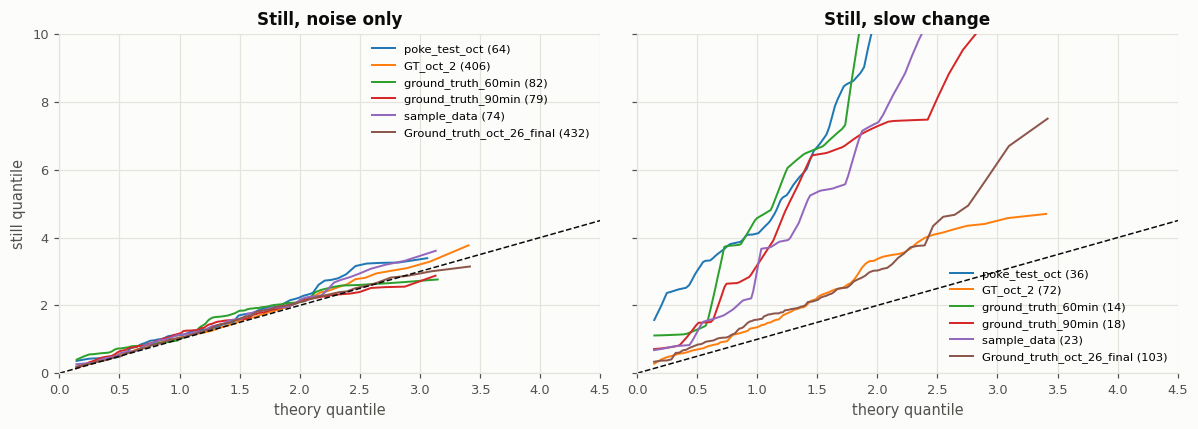

n  median  theory median     q90  \
dataset                   group                                             
poke_test_oct             noise only    64   1.276          1.177   2.608   
                          slow change   36   4.954          1.177  10.952   
GT_oct_2                  noise only   406   1.199          1.196   2.483   
                          slow change   72   1.641          1.196   3.683   
ground_truth_60min        noise only    82   1.386          1.182   2.453   
                          slow change   14   5.434          1.182  14.647   
ground_truth_90min        noise only    79   1.333          1.184   2.253   
                          slow change   18   4.355          1.184   7.447   
sample_data               noise only    74   1.233          1.185   2.298   
                          slow change   23   3.879          1.185   8.529   
Ground_truth_oct_26_final noise only   432   1.238          1.196   2.347   
                          slow change  103   1.793          1.196   3.710   

                                       theory q90   KS p  
dataset                   group                           
poke_test_oct             noise only        2.157  0.252  
                          slow change       2.157  0.000  
GT_oct_2                  noise only        2.277  0.141  
                          slow change       2.277  0.000  
ground_truth_60min        noise only        2.175  0.006  
                          slow change       2.175  0.000  
ground_truth_90min        noise only        2.180  0.118  
                          slow change       2.180  0.000  
sample_data               noise only        2.182  0.604  
                          slow change       2.182  0.000  
Ground_truth_oct_26_final noise only        2.274  0.030  
                          slow change       2.274  0.000

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
q = np.linspace(0.01, 0.99, 99)
for ax, group, title in [(axes[0], ~data["slow"].to_numpy(), "Still, noise only"), (axes[1], data["slow"].to_numpy(), "Still, slow change")]:
    for name in DATASETS:
        rows = still & group & (data["dataset"] == name).to_numpy()
        if rows.sum() >= 10:
            ax.plot(np.quantile(NULL[name], q), np.quantile(z[rows], q), linewidth=1.3, label=f"{name} ({rows.sum()})")
    ax.plot([0, 6], [0, 6], color=INK, linestyle="--", linewidth=1)
    ax.set(xlim=(0, 4.5), ylim=(0, 10), xlabel="theory quantile", title=title)
    ax.legend(fontsize=7.5)
axes[0].set_ylabel("still quantile")
plt.tight_layout()
plt.show()

rows = []
for name in DATASETS:
    for group, label in ((~data["slow"], "noise only"), (data["slow"], "slow change")):
        mask = still & group.to_numpy() & (data["dataset"] == name).to_numpy()
        if mask.sum() >= 10:
            rows.append({"dataset": name, "group": label, "n": mask.sum(), "median": np.median(z[mask]),
                         "theory median": np.median(NULL[name]), "q90": np.quantile(z[mask], 0.9),
                         "theory q90": np.quantile(NULL[name], 0.9),
                         "KS p": stats.ks_2samp(z[mask], NULL[name][:20_000]).pvalue})
display(pd.DataFrame(rows).set_index(["dataset", "group"]).round(3))

The still recordings that carry only noise follow the theory closely, without anything fitted: on the diagonal up to the 90th percentile in all six datasets, medians 1.20 to 1.39 against 1.18 to 1.20, and the KS test finds no difference in four of six. The slow changes lie above it everywhere.

A caveat: the split uses where the power lies over the frames, not how large the score is, but the two are related (a large slow change also raises the score), so the split leans towards low scores. The 10-frame datasets, whose split is weak and keeps 85 % of their still recordings as noise only, are the cleaner evidence. There, *all* still recordings are close to the theory up to about the 90th percentile (step 8).

## Step 10. Does the order of the rays matter?

If the score is a random walk, any order of the same steps gives an equally likely walk. Each still recording's profile is cut into blocks of 4 rays (which keeps the correlation of step 4), the blocks are put in a random order 500 times, and the p-value is the share of shuffles that score at least the real one. For a random walk, the p-values of still recordings are uniform. A leg's arrows point one way in one place, so moving recordings pile up near 0.

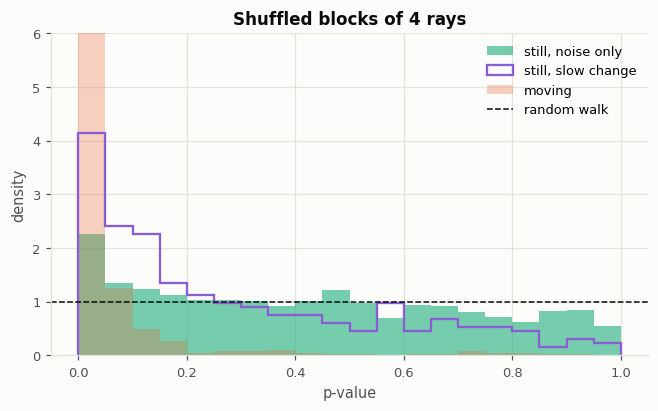

,p < 0.05
"still, noise only",0.113
"still, slow change",0.207
moving,0.868
random walk,0.050


In [15]:
def shuffled_p(rows, block, shuffles=500):
    values = P[rows]
    real = np.abs((values * STEP).mean(axis=1))
    beaten = np.zeros(len(values))
    blocks = K // block
    for _ in range(shuffles):
        offset = rng.integers(block)
        turned = np.roll(values, -offset, axis=1).reshape(len(values), blocks, block)
        order = rng.permuted(np.tile(np.arange(blocks), (len(values), 1)), axis=1)
        mixed = np.take_along_axis(turned, order[:, :, None], axis=1).reshape(len(values), K)
        beaten += np.abs((mixed * STEP).mean(axis=1)) >= real
    return (beaten + 1) / (shuffles + 1)

p_values = shuffled_p(np.arange(len(data)), 4)
fig, ax = plt.subplots(figsize=(7, 3.8))
bins = np.linspace(0, 1, 21)
ax.hist(p_values[still & ~data["slow"].to_numpy()], bins, density=True, color=AQUA, alpha=0.6, label="still, noise only")
ax.hist(p_values[still & data["slow"].to_numpy()], bins, density=True, histtype="step", color=PURPLE, linewidth=1.5, label="still, slow change")
ax.hist(p_values[moving], bins, density=True, color=ORANGE, alpha=0.3, label="moving")
ax.axhline(1, color=INK, linestyle="--", linewidth=1, label="random walk")
ax.set(xlabel="p-value", ylabel="density", title="Shuffled blocks of 4 rays", ylim=(0, 6))
ax.legend()
plt.show()
display(pd.DataFrame({"p < 0.05": {
    "still, noise only": (p_values[still & ~data["slow"].to_numpy()] < 0.05).mean(),
    "still, slow change": (p_values[still & data["slow"].to_numpy()] < 0.05).mean(),
    "moving": (p_values[moving] < 0.05).mean(), "random walk": 0.05}}).round(3))

Still recordings carrying only noise are close to uniform, though not exactly: 11 % below 0.05 against 5 %. Some one-sidedness is left in them; step 11 finds where it comes from. Those with a slow change are one-sided twice as often (21 %), and moving ones nearly always (87 %). (Shuffling single rays instead of blocks would break the correlation of step 4 and shorten every walk, rejecting many noise-only recordings for that reason alone.)

## Step 11. Is the direction new in every recording?

Noise is new in every recording, so the direction of a still mite's arrow, $\varphi_1$, should be unrelated between two consecutive still recordings of the same mite: the mean of $\cos(\varphi_1^{(t+1)} - \varphi_1^{(t)})$ is 0. A positive mean means something one-sided round the mite stays from recording to recording.

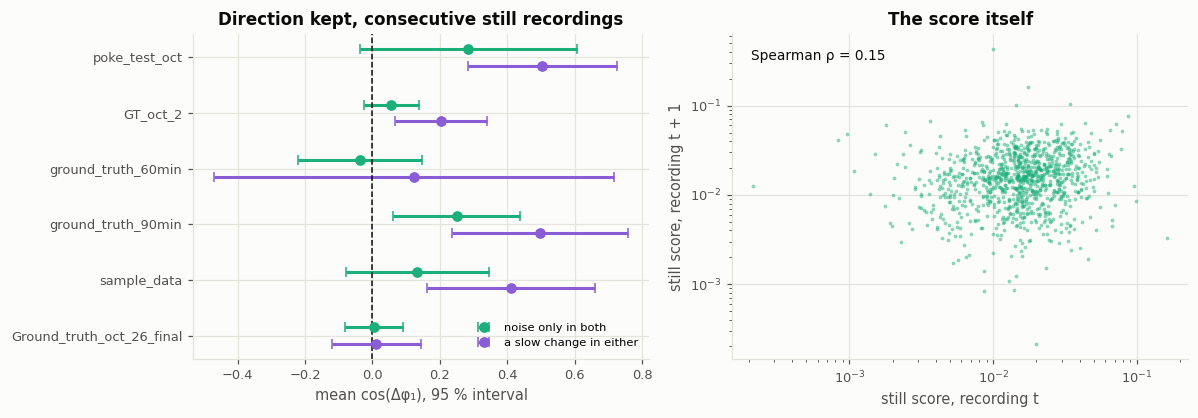

mean                     \
kind                      a slow change in either noise only in both   
dataset                                                                
poke_test_oct                                0.50               0.28   
GT_oct_2                                     0.20               0.06   
ground_truth_60min                           0.12              -0.04   
ground_truth_90min                           0.50               0.25   
sample_data                                  0.41               0.13   
Ground_truth_oct_26_final                    0.01               0.00   

                                            count                     
kind                      a slow change in either noise only in both  
dataset                                                               
poke_test_oct                                28.0               19.0  
GT_oct_2                                     94.0              294.0  
ground_truth_60min                            8.0               56.0  
ground_truth_90min                           13.0               50.0  
sample_data                                  20.0               45.0  
Ground_truth_oct_26_final                   125.0              264.0

In [16]:
data["phase"] = np.angle(CC[:, 1])
by_mite = data.sort_values(["mite", "recording"])
following = by_mite.groupby("mite").shift(-1)
pair = (~by_mite["moving"]) & (following["moving"] == False) & (following["recording"] == by_mite["recording"] + 1)  # noqa: E712
pairs = by_mite[pair].assign(next_phase=following.loc[pair, "phase"], next_score=following.loc[pair, "score"],
                             next_slow=following.loc[pair, "slow"])
pairs["cos"] = np.cos(pairs["next_phase"] - pairs["phase"])
pairs["kind"] = np.where(pairs["slow"] | (pairs["next_slow"] == True), "a slow change in either", "noise only in both")  # noqa: E712

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
table = pairs.groupby(["dataset", "kind"])["cos"].agg(["mean", "sem", "count"]).reset_index()
for offset, (kind, color) in zip((-0.15, 0.15), (("noise only in both", AQUA), ("a slow change in either", PURPLE))):
    part = table[table["kind"] == kind].set_index("dataset").reindex(DATASETS)
    y = np.arange(len(DATASETS)) + offset
    axes[0].errorbar(part["mean"], y, xerr=1.96 * part["sem"], fmt="o", color=color, capsize=3, label=kind)
axes[0].axvline(0, color=INK, linestyle="--", linewidth=1)
axes[0].set(yticks=np.arange(len(DATASETS)), xlabel="mean cos(Δφ₁), 95 % interval", title="Direction kept, consecutive still recordings")
axes[0].set_yticklabels(DATASETS)
axes[0].invert_yaxis()
axes[0].legend(fontsize=7.5, loc="lower right")

axes[1].scatter(pairs["score"], pairs["next_score"], s=6, color=AQUA, alpha=0.5, linewidth=0)
axes[1].set(xscale="log", yscale="log", xlabel="still score, recording t", ylabel="still score, recording t + 1", title="The score itself")
rho = stats.spearmanr(pairs["score"], pairs["next_score"])[0]
axes[1].annotate(f"Spearman ρ = {rho:.2f}", (0.04, 0.92), xycoords="axes fraction", fontsize=9, color=INK)
plt.tight_layout()
plt.show()
display(table.pivot(index="dataset", columns="kind", values=["mean", "count"]).reindex(DATASETS).round(2))

In `poke_test_oct`, `ground_truth_90min` and `sample_data` the direction is kept between consecutive still recordings more than noise allows, most where a slow change is involved but also between noise-only recordings (mean cos 0.13 to 0.28). In the 10-frame datasets there is little or none, as their noise is larger. The score itself hardly carries over (ρ about 0.15).

Is the kept direction each mite's own (a neighbour, a shadow, a leg at rest), or one shared by the whole plate? If it is the plate's, still arrows of *all* mites point the same way in the image. Below, the direction of every still recording's arrow, per dataset (0° points right in the image, as in the app), with the mean direction as an arrow. For noise, the directions are uniform and the arrow is about $1/\sqrt n$ long (the dashed circle).

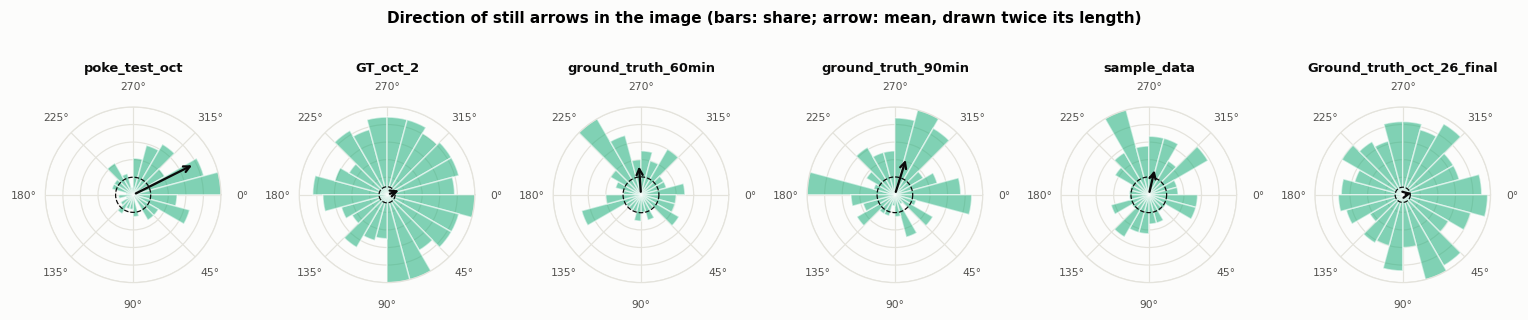

,still,mean length,noise ~ 1/√n,direction (°)
poke_test_oct,100.0,0.39,0.10,-26.59
GT_oct_2,478.0,0.09,0.05,-20.18
ground_truth_60min,96.0,0.18,0.10,-93.92
ground_truth_90min,97.0,0.23,0.10,-72.78
sample_data,97.0,0.16,0.10,-76.90
Ground_truth_oct_26_final,535.0,0.07,0.04,-10.76


In [17]:
fig, axes = plt.subplots(1, 6, figsize=(14, 3.2), subplot_kw={"projection": "polar"})
bins = np.linspace(-np.pi, np.pi, 25)
mean_direction = {}
for ax, name in zip(axes, DATASETS):
    rows = still & (data["dataset"] == name).to_numpy()
    phase = data["phase"].to_numpy()[rows]
    counts, _ = np.histogram(phase, bins)
    share = counts / counts.sum()
    ax.bar(0.5 * (bins[1:] + bins[:-1]), share / share.max(), width=np.diff(bins), color=AQUA, alpha=0.55, edgecolor="white")
    mean = np.exp(1j * phase).mean()
    mean_direction[name] = {"still": rows.sum(), "mean length": abs(mean), "noise ~ 1/√n": 1 / np.sqrt(rows.sum()),
                            "direction (°)": np.degrees(np.angle(mean))}
    ax.annotate("", xy=(np.angle(mean), abs(mean) * 2), xytext=(0, 0), arrowprops={"arrowstyle": "->", "color": INK, "linewidth": 1.5})
    ax.plot(np.linspace(0, 2 * np.pi, 100), np.full(100, 2 / np.sqrt(rows.sum())), color=INK, linestyle="--", linewidth=0.8)
    ax.set_theta_direction(-1)       # clockwise, as the rays go in the image
    ax.set(ylim=(0, 1), yticklabels=[])
    ax.set_title(name, fontsize=8.5)
    ax.tick_params(labelsize=7)
fig.suptitle("Direction of still arrows in the image (bars: share; arrow: mean, drawn twice its length)", fontweight="bold", fontsize=10)
plt.tight_layout()
plt.show()
display(pd.DataFrame(mean_direction).T.round(2))

In the 30- and 90-frame datasets the arrows of still mites prefer one direction in the image, 2 to 4 times more strongly than noise would: in the three 30-frame datasets towards the top of the image (−73° to −94°), in `poke_test_oct` towards the upper right (−27°). The 10-frame datasets show a trace of it (0.07 to 0.09 against a noise level of 0.04 to 0.05). That is not something each mite does on its own: it is shared by the plate. Something on one side of every mite changes slowly during the recording, the same side for all. Two candidates: a lamp that lights the plate from one side and changes slightly over the 1 to 3 s (the app corrects each frame's overall brightness, not a gradient across the patch), or a slow drift of the image that the stabiliser leaves partly in. This notebook can't tell them apart: that needs the frames. This shared part is also what the shuffle test of step 10 and the kept direction above pick up in noise-only recordings.

## Step 12. How the scale depends on the number of frames

For white noise the error of a variance estimated from $N$ frames is about $\sqrt{2/N}$ of the variance, so the walk's steps relative to the profile's level, $\tau/\bar a$, should shrink as $1/\sqrt N$, and the still score with them. Once each score is divided by its own σ, the number of frames should no longer matter.

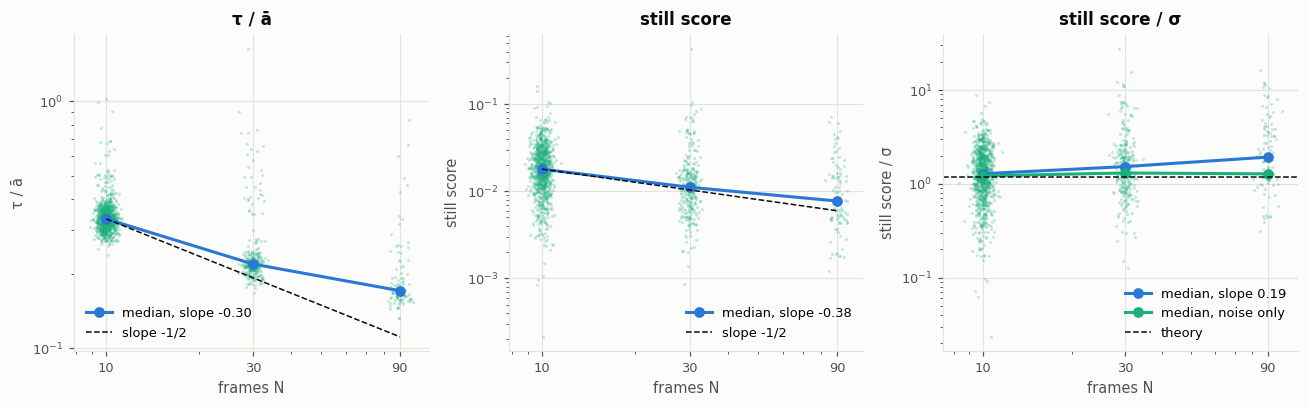

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
lengths = np.array([10, 30, 90])
ratio = (data["tau"] / data["abar"]).to_numpy()
for ax, values, label in [(axes[0], ratio, "τ / ā"), (axes[1], data["score"].to_numpy(), "still score"), (axes[2], z, "still score / σ")]:
    medians = []
    for frames in lengths:
        rows = still & (data["frames"] == frames).to_numpy()
        ax.scatter(frames * np.exp(rng.normal(0, 0.04, rows.sum())), values[rows], s=4, color=AQUA, alpha=0.25, linewidth=0)
        medians.append(np.median(values[rows]))
    medians = np.array(medians)
    slope = np.polyfit(np.log(lengths), np.log(medians), 1)[0]
    ax.plot(lengths, medians, "o-", color=BLUE, label=f"median, slope {slope:.2f}")
    if ax is not axes[2]:
        ax.plot(lengths, medians[0] * np.sqrt(lengths[0] / lengths), color=INK, linestyle="--", linewidth=1, label="slope -1/2")
    else:
        quiet = [np.median(values[still & ~data["slow"].to_numpy() & (data["frames"] == n).to_numpy()]) for n in lengths]
        ax.plot(lengths, quiet, "o-", color=AQUA, label="median, noise only")
        ax.axhline(np.median(NULL["poke_test_oct"]), color=INK, linestyle="--", linewidth=1, label="theory")
    ax.set(xscale="log", yscale="log", xticks=lengths, xlabel="frames N", ylabel=label, title=label)
    ax.set_xticklabels(lengths)
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.legend()
plt.tight_layout()
plt.show()

The step size and the still score fall with $N$, though more slowly than $1/\sqrt N$. The three lengths are also three sets of sessions, so this is only a hint. Divided by their own σ, the noise-only still recordings sit near the theory's median at every length: the noise sets their scale, and the measured σ follows it. All still recordings together rise with $N$, because a longer recording catches more slow change, and that part the noise σ doesn't measure. This also flattens the slopes on the left.

## Step 13. Moving against still, and the threshold

This notebook divides by σ to test the *shape* of still scores; the app does not. Both separate moving from still. Below, the app's score and score / σ, still and moving, on a log axis.

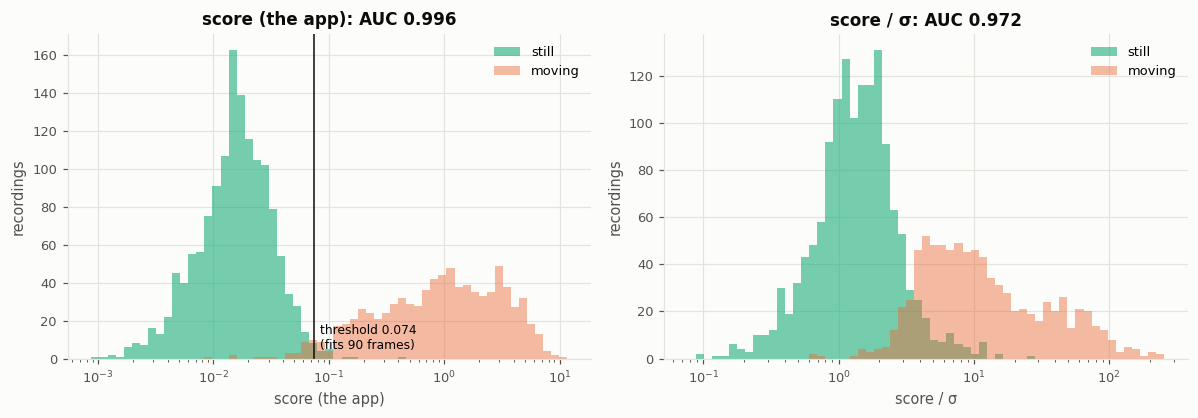

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
for ax, values, label in [(axes[0], data["score"].to_numpy(), "score (the app)"), (axes[1], z, "score / σ")]:
    bins = np.geomspace(np.quantile(values, 0.001), values.max(), 60)
    ax.hist(values[still], bins, color=AQUA, alpha=0.6, label="still")
    ax.hist(values[moving], bins, color=ORANGE, alpha=0.45, label="moving")
    ax.set(xscale="log", xlabel=label, ylabel="recordings", title=f"{label}: AUC {roc_auc_score(moving, values):.3f}")
    ax.legend()
axes[0].axvline(THRESHOLD, color=INK, linewidth=1)
axes[0].annotate("threshold 0.074\n(fits 90 frames)", (THRESHOLD, 5), xytext=(4, 0), textcoords="offset points", fontsize=8)
plt.tight_layout()
plt.show()

What noise alone predicts at the threshold: on `poke_test_oct` (90 frames, the recordings the threshold was set on), the share of still recordings above a threshold, measured, and as the theory gives it from each recording's own σ.

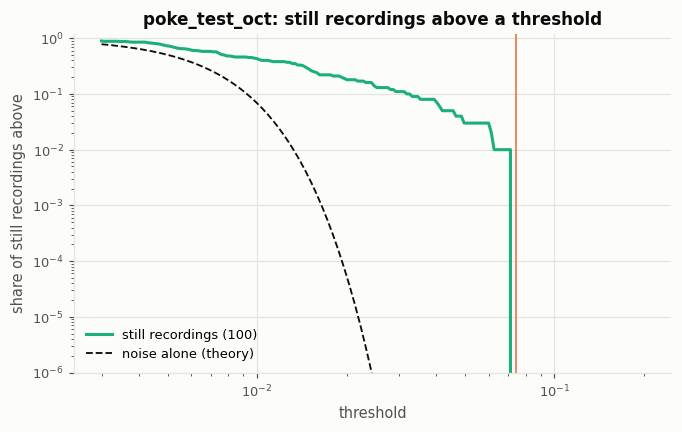

above 0.074: measured 0 of 100, noise alone 1.1e-45


In [20]:
rows = still & poke
scores, sigma = data["score"].to_numpy()[rows], data["sigma_noise"].to_numpy()[rows]
T = np.geomspace(0.003, 0.2, 200)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(T, [(scores > t).mean() for t in T], color=AQUA, label=f"still recordings ({rows.sum()})")
ax.plot(T, [np.exp(-t ** 2 / (2 * sigma ** 2)).mean() for t in T], color=INK, linestyle="--", linewidth=1.2, label="noise alone (theory)")
ax.axvline(THRESHOLD, color=ORANGE, linewidth=1)
ax.set(xscale="log", yscale="log", ylim=(1e-6, 1.2), xlabel="threshold", ylabel="share of still recordings above",
       title="poke_test_oct: still recordings above a threshold")
ax.legend()
plt.show()
print(f"above {THRESHOLD}: measured {(scores > THRESHOLD).sum()} of {rows.sum()}, "
      f"noise alone {np.exp(-THRESHOLD ** 2 / (2 * sigma ** 2)).mean():.1e}")

Noise alone would almost never lift a still mite over the threshold. The still recordings above the theory's curve are the slow changes of step 9: they decide how close still scores come to the threshold, not the camera's noise.

## Step 14. The argument, step by step

1. **The score is the end point of a walk.** It is the length of the mean of 128 arrows, one per direction round the mite, and only the profile's variations $\varepsilon_k$ move it (step 1).
2. **For a still mite those steps are noise, correlated over a few rays.** Neighbouring rays read overlapping pixels (step 4); the walk spreads a little faster than with independent steps (step 3).
3. **Short-range correlation keeps the central limit theorem.** The end point is still Gaussian and the score still Rayleigh, but the scale is not $\tau/\sqrt{2K}$: that formula is 1.8 times too small (step 4), and σ must be measured.
4. **The noise is white over the frames** (step 5), so σ can be measured at the high frame frequencies, where a slow change doesn't reach. Nothing in it comes from the score (step 6).
5. **With that σ, the theory predicts still scores without anything fitted:** the core of the end points is a round Gaussian (step 7), score / σ follows the theory's quantiles in the lower half everywhere and in the 10-frame datasets up to about the 90th percentile (step 8), and up to the 90th percentile for the still recordings that carry only noise (step 9). For those, the order of the rays matters little (step 10), and the number of frames no longer matters once divided by σ (step 12).
6. **The tail is not noise.** The highest still scores carry their power at low frame frequencies: slow one-sided changes too small to be labelled as movement (step 9). Part of it is shared by the whole plate, one direction in the image for all mites (step 11).

So: **a still recording's score is the end point of a random walk round the mite, Rayleigh-distributed with a scale set by the outline's own noise**, for the still recordings whose outline carries only noise; the rest add a small, real, slow change on top. "Brownian" describes the walk round the mite, not the frames: over the frames the noise is white.

**What to write in the report** (`report/fourier_and_brownian_motion.md`): keep the random walk and the Rayleigh distribution; replace $\tau/\sqrt{2K}$ by a measured σ (the noise at $h = 1$, about twice what independent rays give, because neighbouring rays are correlated); and say that the still scores' long tail comes from slow one-sided changes, not from the noise.

**Open questions** that need the frames rather than this notebook: whether the shared direction of step 11 comes from the light or from a drift left by the stabiliser, and how the scale falls with the number of frames within one session (score the 90-frame recordings again from their first 10, 30 and 90 frames).